# The Problem
    This dataset is originally from the National Institute of Diabetes and Digestive and Kidney Diseases. The objective of the dataset is to diagnostically predict whether or not a patient has diabetes, based on certain diagnostic measurements included in the dataset. Several constraints were placed on the selection of these instances from a larger database. In particular, all patients here are females at least 21 years old of Pima Indian heritage.

### Importing Libraries

In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns  
%matplotlib inline 
plt.style.use('fivethirtyeight')

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import Normalizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn import metrics

In [4]:
pima_column_names = ['times_pregnant', 'plasma_glucose_concentration', 'diastolic_blood_pressure', 'triceps_thickness', 'serum_insulin', 'bmi', 'pedigree_function', 'age', 'onset_diabetes']
pima = pd.read_csv('diabetes.csv',names = pima_column_names,skiprows=1)
pima.head()

,times_pregnant,plasma_glucose_concentration,diastolic_blood_pressure,triceps_thickness,serum_insulin,bmi,pedigree_function,age,onset_diabetes
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
pima.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
Pregnancies                 768 non-null int64
Glucose                     768 non-null int64
BloodPressure               768 non-null int64
SkinThickness               768 non-null int64
Insulin                     768 non-null int64
BMI                         768 non-null float64
DiabetesPedigreeFunction    768 non-null float64
Age                         768 non-null int64
Outcome                     768 non-null int64
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


    There clearly are no null values in the data(Remember this please...). However, what other preliminary analysis do you think are necessary to get started?

### Exploratory data analysis (EDA)
    To identify our missing values we will begin with an EDA of our dataset. We will be using some useful python packages, pandas and numpy, to store our data and make some simple calculations as well as some popular visualization tools to see what the distribution of our data looks like. Let's begin and dive into some code. First, we will do some imports:

In [6]:
pima['onset_diabetes'].value_counts(normalize=True) 

0    0.651042
1    0.348958
Name: onset_diabetes, dtype: float64

    If our eventual goal is to exploit patterns in our data in order to predict the onset of diabetes, let us try to visualize some of the differences between those that developed diabetes and those that did not. Our hope is that the histogram will reveal some sort of pattern, or obvious difference in values between the classes of prediction

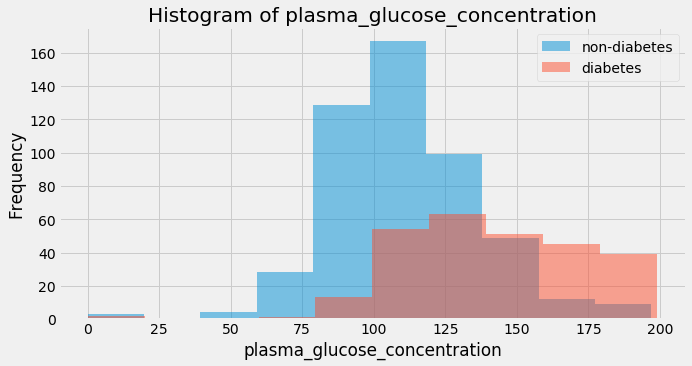

In [8]:
col = 'plasma_glucose_concentration'
plt.figure(figsize=(10,5))
plt.hist(pima[pima['onset_diabetes']==0][col], 10, alpha=0.5, label='non-diabetes')
plt.hist(pima[pima['onset_diabetes']==1][col], 10, alpha=0.5, label='diabetes')
plt.legend(loc='upper right')
plt.xlabel(col)
plt.ylabel('Frequency')
plt.title('Histogram of {}'.format(col))
plt.show()

    What do you understand from the histograms?
---

    It seems that this histogram is showing us a considerable difference between plasma_glucose_concentration between the two prediction classes. Let's show the same histogram style for multiple columns as follows

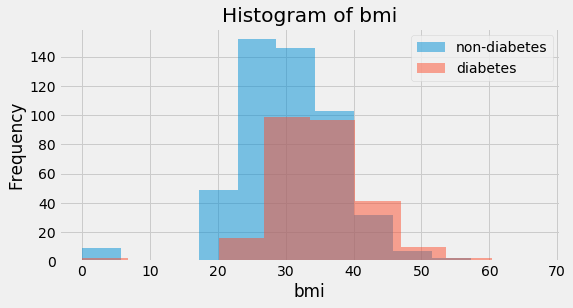

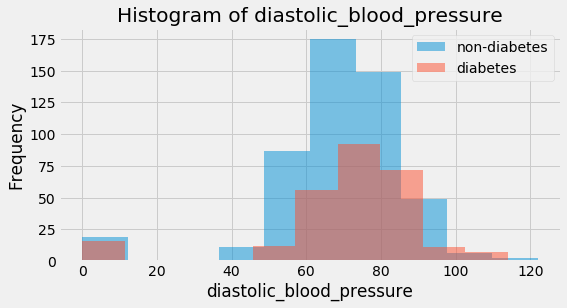

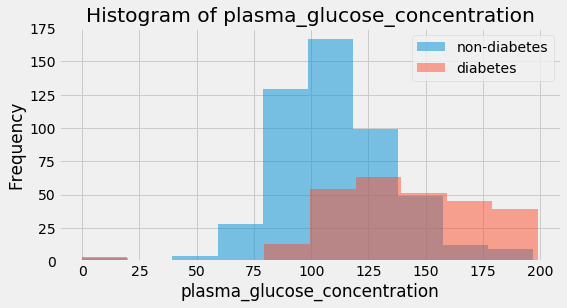

In [9]:
for col in ['bmi', 'diastolic_blood_pressure', 'plasma_glucose_concentration']:
    plt.figure(figsize=(8,4))
    plt.hist(pima[pima['onset_diabetes']==0][col], 10, alpha=0.5, label='non-diabetes')
    plt.hist(pima[pima['onset_diabetes']==1][col], 10, alpha=0.5, label='diabetes')
    plt.legend(loc='upper right')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.title('Histogram of {}'.format(col))
    plt.show()

    We can definitely see some differences simply by looking at just a few histograms. For example, there seems to be a large jump in plasma_glucose_concentration for those who will eventually develop diabetes. To solidify this, perhaps we can visualize a linear correlation matrix in an attempt to quantify the relationship between these variables. 

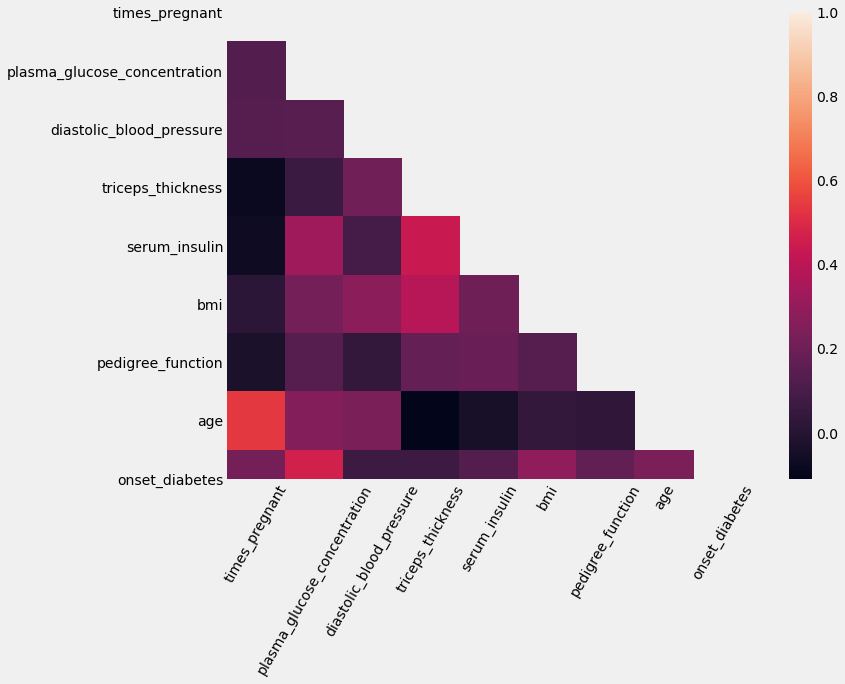

In [13]:
# look at the heatmap of the correlation matrix of our dataset
plt.figure(figsize=(12,8))
corr=round(pima.corr(),2)
mask = np.triu(np.ones_like(corr, dtype=np.bool))
sns.heatmap(corr,mask=mask, square=True, annot=False)
plt.xticks(rotation=60)
plt.show()
# plasma_glucose_concentration definitely seems to be an interesting feature here

#Following is the correlation matrix of our dataset. This is showing us the correlation amongst 
#the different columns in our Pima dataset. The output is as follows:

    Which features are most correlated? are there any features that would lead to multiple correlation
---

    This correlation matrix is showing a strong correlation between plasma_glucose_concentration and onset_diabetes. Let's take a further look at the numerical correlations for the onset_diabetes column
    There aren't features that would result in too much multiple correlation

In [14]:
pima.corr()['onset_diabetes'] 

times_pregnant                  0.221898
plasma_glucose_concentration    0.466581
diastolic_blood_pressure        0.065068
triceps_thickness               0.074752
serum_insulin                   0.130548
bmi                             0.292695
pedigree_function               0.173844
age                             0.238356
onset_diabetes                  1.000000
Name: onset_diabetes, dtype: float64

    We will explore the powers of correlation later, during Feature Construction, but for now we are using exploratory data analysis (EDA) to hint at the fact that the plasma_glucose_concentration column will be an important factor in our prediction of the onset of diabetes.

In [16]:
pima.describe()

,times_pregnant,plasma_glucose_concentration,diastolic_blood_pressure,triceps_thickness,serum_insulin,bmi,pedigree_function,age,onset_diabetes
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


    This shows us quite quickly some basic stats such as mean, standard deviation, and some different percentile measurements of our data. But, notice that the minimum value of the BMI column is 0. That is medically impossible; there must be a reason for this to happen. Perhaps the number zero has been encoded as a missing value instead of the None value or a missing cell. Upon closer inspection, we see that the value 0 appears as a minimum value for the following columns:

    1. times_pregnant
    2. plasma_glucose_concentration
    3. diastolic_blood_pressure
    4. triceps_thickness
    5. serum_insulin
    6. bmi
    7. onset_diabetes

    Because zero is a class for onset_diabetes and 0 is actually a viable number for times_pregnant, we may conclude that the number 0 is encoding missing values for:

    1. plasma_glucose_concentration
    2. diastolic_blood_pressure
    3. triceps_thickness
    4. serum_insulin
    5. bmi


    If no documentation is available, some common values used instead of missing values are:

    1. 0 (for numerical values)
    2. unknown or Unknown (for categorical variables)
    3. ? (for categorical variables)
    The rest is based on the domain knowledge and intuition

### Dealing with missing values in a dataset

    When working with data, one of the most common issues a data scientist will run into is the problem of missing data. Most commonly, this refers to empty cells (row/column intersections) where the data just was not acquired for whatever reason. This can become a problem for many reasons; notably, when applying learning algorithms to data with missing values, most (not all) algorithms are not able to cope with missing values. 

    There are 2 most commonly used ways to deal with null values:
    1. Remove rows with missing values in them
    2. Impute (fill in) missing values
    
    Each method will clean our dataset to a point where a learning algorithm can handle it, but each method will have its pros and cons.

In [17]:
# Our number of missing values is (incorrectly) 0
pima['serum_insulin'].isnull().sum()
pima['serum_insulin'] = pima['serum_insulin'].map(lambda x:x if x != 0 else None)
# manually replace all 0's with a None value

pima['serum_insulin'].isnull().sum()

374

In [18]:
columns = ['serum_insulin', 'bmi', 'plasma_glucose_concentration', 'diastolic_blood_pressure', 'triceps_thickness']

for col in columns:
    pima[col].replace([0], [None], inplace=True)

    We should now be able to see the actual number of missing values

In [19]:
pima.isnull().sum()

times_pregnant                    0
plasma_glucose_concentration      5
diastolic_blood_pressure         35
triceps_thickness               227
serum_insulin                   374
bmi                              11
pedigree_function                 0
age                               0
onset_diabetes                    0
dtype: int64

In [20]:
pima.describe()

,times_pregnant,serum_insulin,pedigree_function,age,onset_diabetes
count,768.000000,394.000000,768.000000,768.000000,768.000000
mean,3.845052,155.548223,0.471876,33.240885,0.348958
std,3.369578,118.775855,0.331329,11.760232,0.476951
min,0.000000,14.000000,0.078000,21.000000,0.000000
25%,1.000000,76.250000,0.243750,24.000000,0.000000
50%,3.000000,125.000000,0.372500,29.000000,0.000000
75%,6.000000,190.000000,0.626250,41.000000,1.000000
max,17.000000,846.000000,2.420000,81.000000,1.000000


In [21]:
pima['plasma_glucose_concentration'].mean(), pima['plasma_glucose_concentration'].std()

(121.6867627785059, 30.53564107280403)

    Let's try the ways of dealing with missing data.
    Pop Quiz: Which of the two most common mentioned methods do you think is suitable for this scenario? How do you get to a conclusion one is better than the other?
---

    We will see how one will be better than other, follow along...

#### Removing rows with null values
    Evidently the easiest way of dealing with null values is removing rows with null. This will result in a dense matrix having only information that makes sense. We can do the operation with a built in pandas function.

In [22]:
pima_dropped = pima.dropna()

In [25]:
num_rows_remained = (pima.shape[0] - pima_dropped.shape[0])/float(pima.shape[0])
num_rows_remained

0.4895833333333333

    We lost about 51% of the rows from the original dataset, and if we think about this from a machine learning perspective, even though now we have clean data with everything filled in, we aren't really learning as much as we possibly could be by ignoring over half of the data's observations. That's like a doctor trying to understand how heart attacks happen, ignoring over half of their patients coming in for check-ups.

    Let's perform some more EDA on the dataset and compare the statistics about the data from before and after dropping the missing-values rows:

In [26]:
# split of trues and falses before rows dropped
pima['onset_diabetes'].value_counts(normalize=True)

0    0.651042
1    0.348958
Name: onset_diabetes, dtype: float64

In [27]:
# split of trues and falses after rows dropped
pima_dropped['onset_diabetes'].value_counts(normalize=True)  

0    0.668367
1    0.331633
Name: onset_diabetes, dtype: float64

    It seems that the binary response stayed relatively the same during the drastic transformation of our dataset. Let's take a look at the shape of our data by comparing the average values of columns before and after the transformation

In [28]:
# Mean before dropping null rows
pima.mean()

times_pregnant                    3.845052
plasma_glucose_concentration    121.686763
diastolic_blood_pressure         72.405184
triceps_thickness                29.153420
serum_insulin                   155.548223
bmi                              32.457464
pedigree_function                 0.471876
age                              33.240885
onset_diabetes                    0.348958
dtype: float64

In [29]:
# mean after dropping null rows
pima_dropped.mean()

times_pregnant                    3.301020
plasma_glucose_concentration    122.627551
diastolic_blood_pressure         70.663265
triceps_thickness                29.145408
serum_insulin                   156.056122
bmi                              33.086224
pedigree_function                 0.523046
age                              30.864796
onset_diabetes                    0.331633
dtype: float64

In [30]:
# % change in means
(pima_dropped.mean() - pima.mean()) / pima.mean()

times_pregnant                 -0.141489
plasma_glucose_concentration    0.007731
diastolic_blood_pressure       -0.024058
triceps_thickness              -0.000275
serum_insulin                   0.003265
bmi                             0.019372
pedigree_function               0.108439
age                            -0.071481
onset_diabetes                 -0.049650
dtype: float64

    It makes better sense plotting the % changes on a graph

(array([0, 1, 2, 3, 4, 5, 6, 7, 8]), <a list of 9 Text xticklabel objects>)

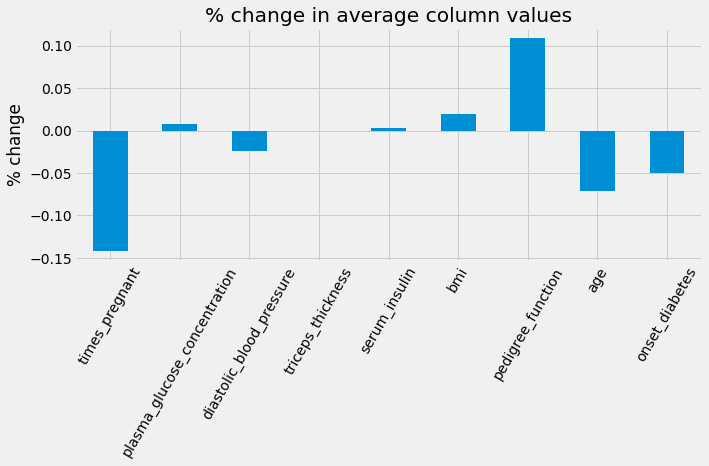

In [36]:
# % change in means as a bar chart
plt.figure(figsize=(10,4))
ax = ((pima_dropped.mean() - pima.mean()) / pima.mean()).plot(kind='bar', title='% change in average column values')
ax.set_ylabel('% change')
plt.xticks(rotation=60)


    We can see that the number of times_pregnant variable average fell 14% after dropping missing values, which is a big change! The pedigree_function also rose 11%, another big leap. We can see how dropping rows (observations) severely affects the shape of the data and we should try to retain as much data as possible. Before moving on to the next method of dealing with missing values, let's introduce some actual machine learning into the mix.

### Modeling after dropping rows with null

In [37]:
X_dropped = pima_dropped.drop('onset_diabetes', axis=1)
y_dropped = pima_dropped['onset_diabetes']

In [40]:
#Let's use GridSearch
knn_params = {'n_neighbors':[1, 2, 3, 4, 5, 6, 7]}
knn = KNeighborsClassifier()

grid = GridSearchCV(knn, knn_params)
grid.fit(X_dropped, y_dropped)

print (grid.best_score_, grid.best_params_)

0.7348263550795197 {'n_neighbors': 7}


    Now we have seen the performance after removing rows with null. What is the problem with this method?
---

    When the null rows are dropped 51% of data is lost irrespective of which we have an accuracy of 73.4%. That's pretty good given the magnitude of our data, but we don't have a proper basis to say this isn't by chance. Moreover, more the data we have more the information about population.
    So the only problem is we can't be sure this is an actual representation of population.

#### Imputing the missing values in data
    Imputing is the more involved method of dealing with missing values. By imputing, we refer to the act of filling in missing data values with numerical quantities that are somehow ascertained from existing knowledge/data. We have a few options on how we can fill in these missing values, the most common of them being filling in missing values with the average value for the rest of the column

In [41]:
pima.isnull().sum()

times_pregnant                    0
plasma_glucose_concentration      5
diastolic_blood_pressure         35
triceps_thickness               227
serum_insulin                   374
bmi                              11
pedigree_function                 0
age                               0
onset_diabetes                    0
dtype: int64

    Let's look at the five rows where plasma_glucose_concentration is missing:

In [42]:
empty_plasma_index = pima[pima['plasma_glucose_concentration'].isnull()].index
pima.loc[empty_plasma_index]['plasma_glucose_concentration']

75     None
182    None
342    None
349    None
502    None
Name: plasma_glucose_concentration, dtype: object

In [43]:
# fill the column's missing values with the mean of the rest of the column
pima['plasma_glucose_concentration'].fillna(pima['plasma_glucose_concentration'].mean(), inplace=True)
pima.isnull().sum()

times_pregnant                    0
plasma_glucose_concentration      0
diastolic_blood_pressure         35
triceps_thickness               227
serum_insulin                   374
bmi                              11
pedigree_function                 0
age                               0
onset_diabetes                    0
dtype: int64

In [44]:
pima.loc[empty_plasma_index]['plasma_glucose_concentration']

75     121.686763
182    121.686763
342    121.686763
349    121.686763
502    121.686763
Name: plasma_glucose_concentration, dtype: float64

    Great! Let's use a module in the scikit-learn preprocessing class (the documentation can be found at http://scikit-learn.org/stable/modules/classes.html#module-sklearn.preprocessing) called the Imputer

In [50]:
imputer = SimpleImputer(strategy='mean')
pima_imputed = imputer.fit_transform(pima)
pima_imputed = pd.DataFrame(pima_imputed, columns=pima_column_names)


    Can you find why we have created new dataframe after applying the imputer?
---

    Imputer returns an n dimensional array and hence we explicitly convert it to a dataframe

In [51]:
pima_imputed.head()

,times_pregnant,plasma_glucose_concentration,diastolic_blood_pressure,triceps_thickness,serum_insulin,bmi,pedigree_function,age,onset_diabetes
0,6.0,148.0,72.0,35.00000,155.548223,33.6,0.627,50.0,1.0
1,1.0,85.0,66.0,29.00000,155.548223,26.6,0.351,31.0,0.0
2,8.0,183.0,64.0,29.15342,155.548223,23.3,0.672,32.0,1.0
3,1.0,89.0,66.0,23.00000,94.000000,28.1,0.167,21.0,0.0
4,0.0,137.0,40.0,35.00000,168.000000,43.1,2.288,33.0,1.0


In [52]:
pima_imputed.isnull().sum()  # no missing values

times_pregnant                  0
plasma_glucose_concentration    0
diastolic_blood_pressure        0
triceps_thickness               0
serum_insulin                   0
bmi                             0
pedigree_function               0
age                             0
onset_diabetes                  0
dtype: int64

In [58]:
knn = KNeighborsClassifier()
X_imputed = pima_imputed.drop('onset_diabetes', axis=1)
print ("learning from {} rows".format(X_imputed.shape[0]))
y_imputed = pima_imputed['onset_diabetes']

knn_params = {'n_neighbors':[1, 2, 3, 4, 5, 6, 7]}
grid = GridSearchCV(knn, knn_params)
grid.fit(X_imputed, y_imputed)

print (grid.best_score_, grid.best_params_)

learning from 768 rows
0.7292335115864528 {'n_neighbors': 7}


#### Let's try imputing with 0

In [59]:
knn = KNeighborsClassifier()
pima_zero = pima.fillna(0) # impute values with 0

X_zero = pima_zero.drop('onset_diabetes', axis=1)
print ("learning from {} rows".format(X_zero.shape[0]))
y_zero = pima_zero['onset_diabetes']

knn_params = {'n_neighbors':[1, 2, 3, 4, 5, 6, 7]}
grid = GridSearchCV(knn, knn_params)
grid.fit(X_zero, y_zero)

print (grid.best_score_, grid.best_params_)
# if the values stayed at 0, our accuracy goes down



learning from 768 rows
0.7409387997623291 {'n_neighbors': 7}


    The highest accuracy we obtained till now is when we dropped all the columns with null values. So that will be our benchmark. We can readily consider all the models with accuracy more than 74.4%

### Pipelines in machine learning

    When we talk about pipelines in machine learning, we are usually talking about the fact that data is only passed through a learning algorithm raw, but also through a variety of preprocessing steps and even multiple learning algorithms before the final output is interpreted. Because it is so common to have several steps and transformation and prediction within a single machine learning pipeline, scikit-learn has a built-in module for building these pipelines.

    Pipelines are especially important because it is actually improper to not use a pipeline when imputing values using the Imputer class. This is because the goal of the learning algorithm is to generalize the patterns in the training set in order to apply those patterns to the testing set. If we impute values for the entire dataset before splitting the set and applying learning algorithms, then we are cheating and our models are not actually learning any patterns. To visualize this concept, let's take a single train test split, a potential one of many during a cross-validation training phase.

In [61]:
X = pima[['serum_insulin']].copy()
y = pima['onset_diabetes'].copy()

X.isnull().sum()

serum_insulin    374
dtype: int64

In [62]:
# the improper way.. imputing values BEFORE splitting
entire_data_set_mean = X.mean()    # take the entire datasets mean
X = X.fillna(entire_data_set_mean) # and use it to fill in the missing spots
print (entire_data_set_mean)

serum_insulin    155.548223
dtype: float64


In [64]:
# Take the split using a random state so that we can examine the same split.
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=99)

In [65]:
# Now, let's fit a KNN model to the training and testing sets:

knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
knn.score(X_test, y_test)

0.65625

In [66]:
# the proper way.. imputing values AFTER splitting
from sklearn.model_selection import train_test_split

X = pima[['serum_insulin']].copy()
y = pima['onset_diabetes'].copy()

# using the same random state to obtain the same split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=99)

X.isnull().sum()

serum_insulin    374
dtype: int64

    Now, instead of taking the mean of the entire X matrix, we will properly only do so for the training set and use that value to fill in missing cells in both the training and test set

In [67]:
training_mean = X_train.mean()
X_train = X_train.fillna(training_mean)
X_test = X_test.fillna(training_mean)

print (training_mean) 

serum_insulin    158.546053
dtype: float64


    Notice the difference in mean when we imputed before split(155.5) and after splitting(158.54)

In [68]:
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
print (knn.score(X_test, y_test))

0.4895833333333333


    This accuracy is far worse than what we had till now, why would we want to use such a method that would reduce the perfromance of our model?
---

    The reason for using only training data mean to impute null is, what if we get only 1 new record that too with null in one feature? we can't use mean of the test set, we will have to use what we already have and that is the training data. Moreover, this is the original performance of our model.
    
    To accomodate this process of imputing with training data's characters we use pipelines

In [75]:
knn = KNeighborsClassifier() 
mean_impute = Pipeline([('imputer', SimpleImputer(strategy='mean')), ('classify', knn)])

X = pima.drop('onset_diabetes', axis=1)
y = pima['onset_diabetes']

knn_params = {'classify__n_neighbors':[1, 2, 3, 4, 5, 6, 7]}
grid = GridSearchCV(mean_impute, knn_params)
grid.fit(X, y)

print (grid.best_score_, grid.best_params_)

0.7318394024276378 {'classify__n_neighbors': 7}


    A few new things to note. First off, our Pipeline has two steps:
    
    An Imputer with strategy= mean
    A classifier of type KNN
    Secondly, we had to redefine our param dict for the grid search as we have to specify exactly to which step of the pipeline the n_neighbors parameter belongs:

In [77]:
knn = KNeighborsClassifier()  # instantiate a KNN model

median_impute = Pipeline([('imputer', SimpleImputer(strategy='median')), ('classify', knn)])
X = pima.drop('onset_diabetes', axis=1)
y = pima['onset_diabetes']

knn_params = {'classify__n_neighbors':[1, 2, 3, 4, 5, 6, 7]}
grid = GridSearchCV(median_impute, knn_params)
grid.fit(X, y)

print (grid.best_score_, grid.best_params_)

0.7292589763177999 {'classify__n_neighbors': 7}


    Here, the only difference is that our pipeline will try a different strategy of imputing median, wherein the missing values will be filled in the median of the remaining values. It is important to reiterate that our accuracies may be lower than the model's fit on the dropped rows, but they were made on more than twice the size of the dataset with missing values! And they were still better than leaving them all at 0, as the data was originally presented to us.

### Standardization and normalization

    Up until now, we have dealt with identifying the types of data as well as the ways data can be missing and finally, the ways we can fill in missing data. Now, let's talk about how we can manipulate our data (and our features) in order to enhance our machine pipelines further. So far, we have tried four different ways of manipulating our dataset, and the best cross-validated accuracy we have achieved with a KNN model is .745. If we look back at some of the EDA we have previously done, we will notice something about our features

In [80]:
impute = SimpleImputer(strategy='mean')
pima_imputed_mean = pd.DataFrame(impute.fit_transform(pima), columns=pima_column_names)

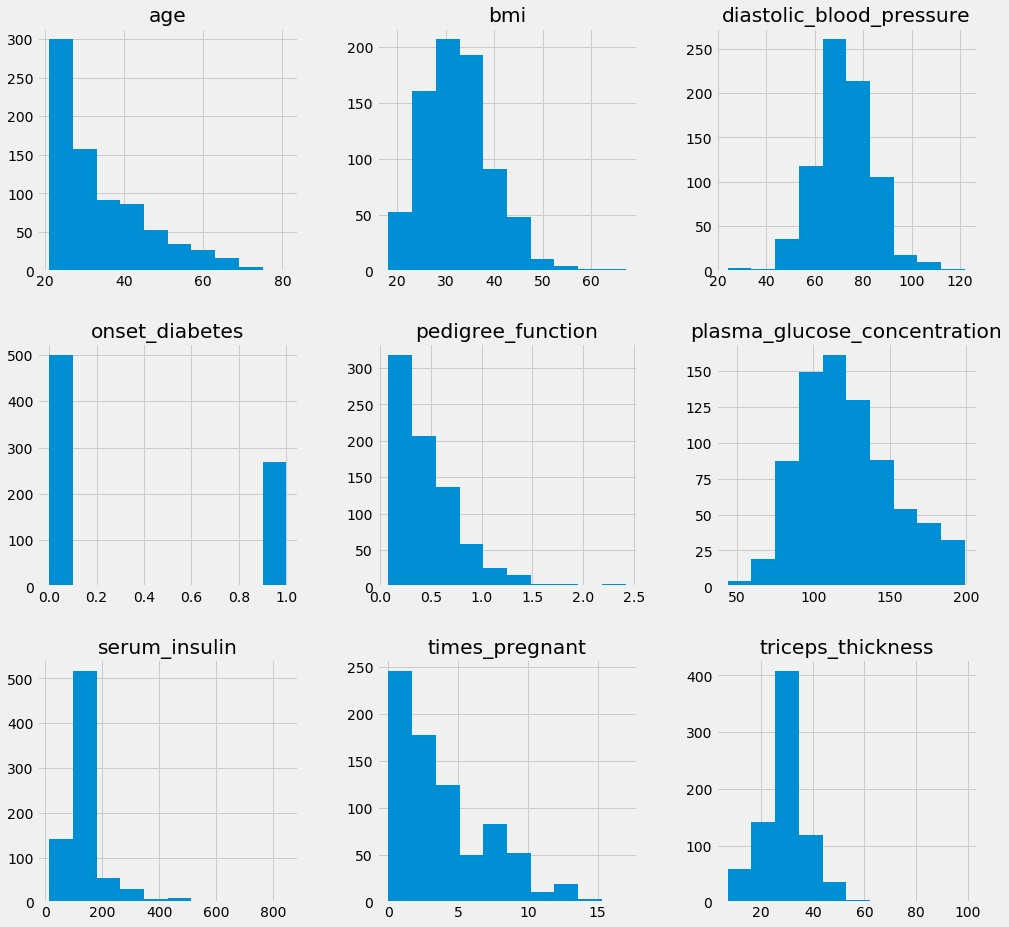

In [82]:
pima_imputed_mean.hist(figsize=(15, 15))
plt.show()

In [73]:
pima_imputed_mean.describe()

,times_pregnant,plasma_glucose_concentration,diastolic_blood_pressure,triceps_thickness,serum_insulin,bmi,pedigree_function,age,onset_diabetes
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.153420,155.548223,32.457464,0.471876,33.240885,0.348958
std,3.369578,30.435949,12.096346,8.790942,85.021108,6.875151,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.202592,29.153420,155.548223,32.400000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,155.548223,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


    Notice anything off about the data from histogram and descriptive stats?
---

    The scale of features is very different.
    
    But why does this matter? Well, some machine learning models rely on learning methods that are affected greatly by the scale of the data, meaning that if we have a column such as diastolic_blood_pressure that lives between 24 and 122, and an age column between 21 and 81, then our learning algorithms will not learn optimally. To really see the differences in scales, let's invoke two optional parameters in the histogram method, sharex and sharey, so that we can see each graph on the same scale as every other graph

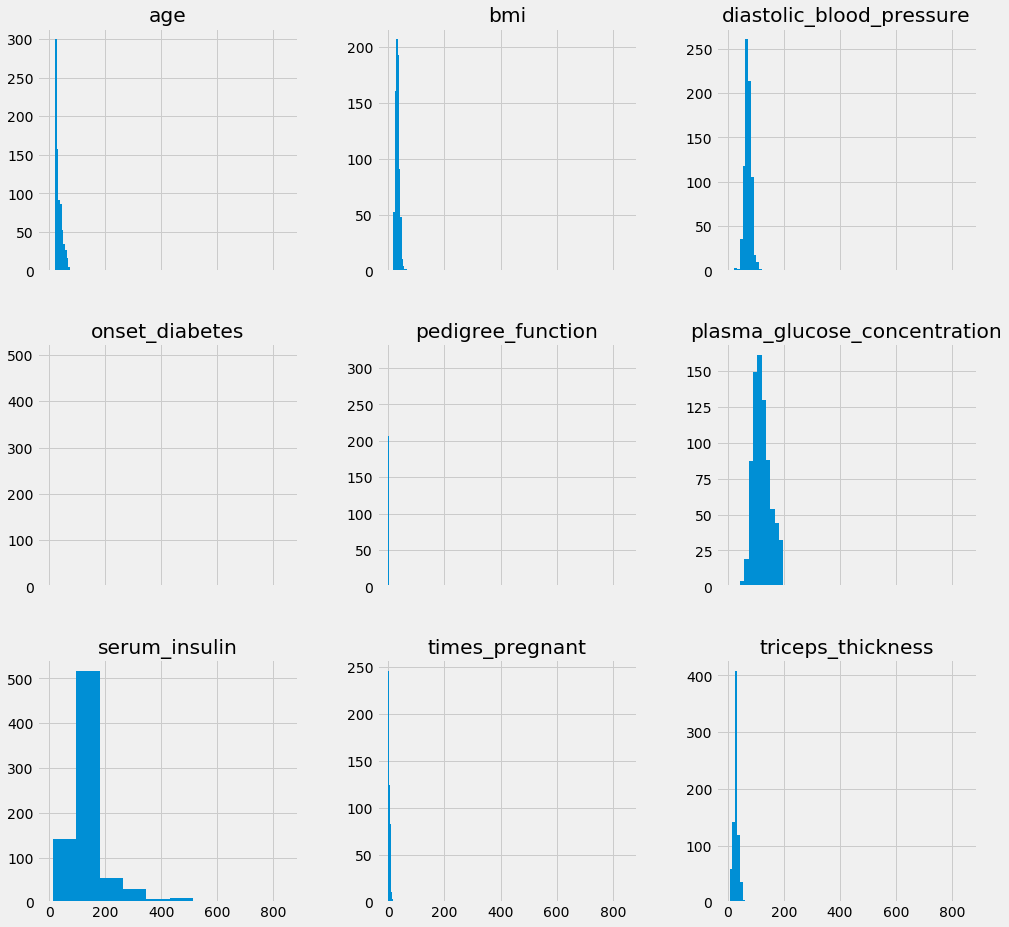

In [83]:
pima_imputed_mean.hist(figsize=(15, 15), sharex=True)
plt.show()

    It is quite clear that our data all lives on vastly different scales. Data engineers have options on how to deal with this problem in our machine learning pipelines that are under a family of operations called normalization. Normalization operations are meant to align and transform both columns and rows to a consistent set of rules. For example, a common form of normalization is to transform all quantitative columns to be between a consistent and static range of values (for example all values must be between 0 and 1). We may also impose mathematical rules such as, all columns must have the same mean and standard deviation so that they appear nicely on the same histogram (unlike the pima histograms we computed recently). Normalization techniques are meant to level the playing field of data by ensuring that all rows and columns are treated equally under the eyes of machine learning.

    We will focus on three methods of data normalization:
    1. Z-score standardization
    2. Min-max scaling
    3. Row normalization
    
    The first two deal specifically with altering features in place, while the third option actually manipulates the rows of the data, but is still just as pertinent as the first two.

### Z-score standardization
    The most common of the normalization techniques, z-score standardization, utilizes a very simple statistical idea of a z-score. The output of a z-score normalization are features that are re-scaled to have a mean of zero and a standard deviation of one. By doing this, by re-scaling our features to have a uniform mean and variance (square of standard deviation), then we allow models such as KNN to learn optimally and not skew towards larger scaled features. The formula is simple: for every column, we replace the cells with the following value:

    z = (x - μ) / σ

    Where:
    1. z is our new value (z-score)
    2. x is the previous value of the cell
    3. μ is the mean of the column
    4. σ is the standard deviation of the columns

In [75]:
print (pima['plasma_glucose_concentration'].head())

0    148.0
1     85.0
2    183.0
3     89.0
4    137.0
Name: plasma_glucose_concentration, dtype: float64


    Let's manually compute z-scores for every value in our column

In [84]:
# get the mean of the column
mu = pima['plasma_glucose_concentration'].mean()

# get the standard deviation of the column
sigma = pima['plasma_glucose_concentration'].std()

# calculate z scores for every value in the column.
print (((pima['plasma_glucose_concentration'] - mu) / sigma).head())

0    0.864545
1   -1.205376
2    2.014501
3   -1.073952
4    0.503130
Name: plasma_glucose_concentration, dtype: float64


    We see that every single value in the column will be replaced, and also notice how now some of them are negative. This is because the resulting values represent a distance from the mean. So, if a value originally was below the mean of the column, the resulting z-score will be negative. Of course, in scikit-learn, we have built-in objects 

Text(0.5, 1.0, 'Distribution of plasma_glucose_concentration')

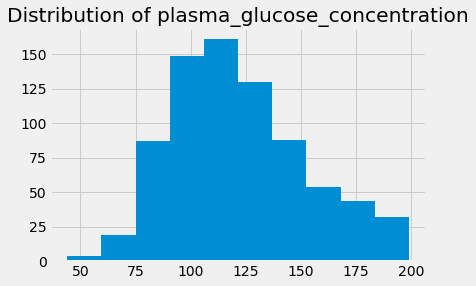

In [86]:
# mean and std before z score standardizing
pima['plasma_glucose_concentration'].mean(), pima['plasma_glucose_concentration'].std()

(121.68676277850591, 30.435948867207657)


ax = pima['plasma_glucose_concentration'].hist()
ax.set_title('Distribution of plasma_glucose_concentration')

    Here, we can see the distribution of the column before doing anything. Now, let's apply a z-score scaling

In [87]:
scaler = StandardScaler()

glucose_z_score_standardized = scaler.fit_transform(pima[['plasma_glucose_concentration']])
glucose_z_score_standardized.mean(), glucose_z_score_standardized.std()

(-3.561965537339044e-16, 1.0)

    We can see that after we apply our scaler to the column, mean drops to very small value and our standard deviation is one. Furthermore, if we take a look at the distribution of values across our recently scaled data

Text(0.5, 1.0, 'Distribution of plasma_glucose_concentration after Z Score Scaling')

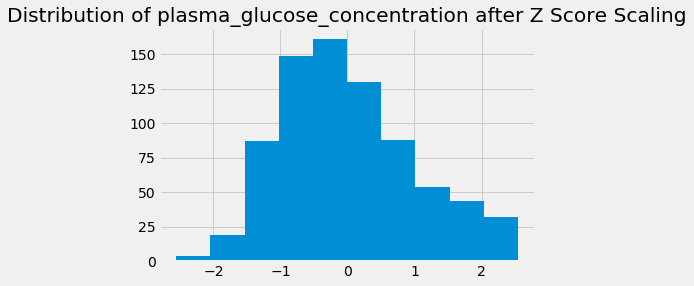

In [88]:
ax = pd.Series(glucose_z_score_standardized.reshape(-1,)).hist()
ax.set_title('Distribution of plasma_glucose_concentration after Z Score Scaling')

    We will notice that our x axis is now much more constrained, while our y axis is unchanged. Also note that the shape of the data is unchanged entirely. Let's take a look at the histograms of our DataFrame after we apply a z-score transformation on every single column. When we do this, the StandardScaler will compute a mean and standard deviation for every column separately

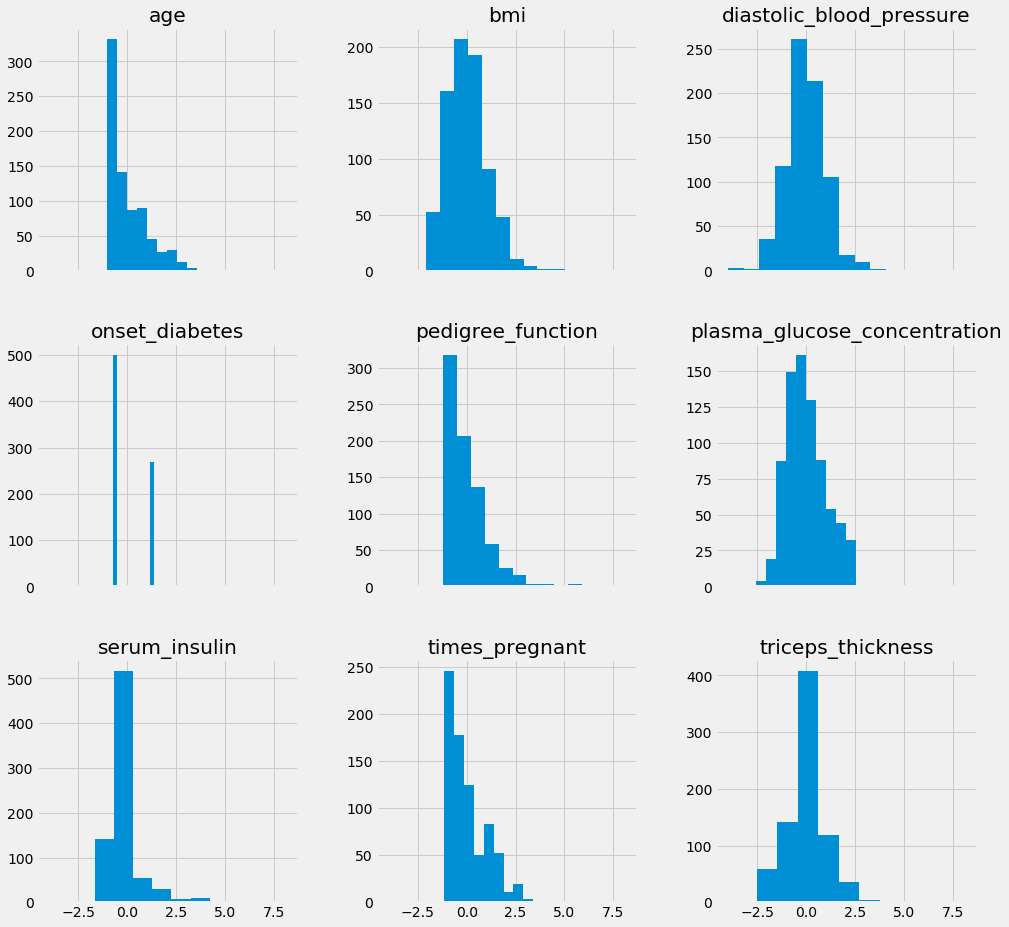

In [89]:
scale = StandardScaler() # instantiate a z-scaler object

pima_imputed_mean_scaled = pd.DataFrame(scale.fit_transform(pima_imputed_mean), columns=pima_column_names)
pima_imputed_mean_scaled.hist(figsize=(15, 15), sharex=True)
plt.show()

    Notice that our x axes are all now much more constrained across the entire dataset. Let's now plug a StandardScaler into our machine learning pipeline from before, why don't you try doing it by yourself before you see the actual code?

In [90]:
mean_impute_standardize = Pipeline([('imputer', SimpleImputer()), ('standardize', StandardScaler()), ('classify', knn)])
X = pima.drop('onset_diabetes', axis=1)
y = pima['onset_diabetes']

knn_params = {'imputer__strategy':['mean', 'median'], 'classify__n_neighbors':[1, 2, 3, 4, 5, 6, 7]}
grid = GridSearchCV(mean_impute_standardize, knn_params)
grid.fit(X, y)

print (grid.best_score_, grid.best_params_)

0.7539173245055598 {'classify__n_neighbors': 7, 'imputer__strategy': 'mean'}


    Now we can clearly see our model has already started outperforming the benchmark. That's good progress we have till now

### The min-max scaling method

    Min-max scaling is similar to z-score normalization in that it will replace every value in a column with a new value using a formula. In this case, that formula is:

    m = (x -xmin) / (xmax -xmin)

    Where:

    1. m is our new value
    2. x is the original cell value
    3. xmin is the minimum value of the column
    4. xmax is the maximum value of the column

In [92]:
min_max = MinMaxScaler()
pima_min_maxed = pd.DataFrame(min_max.fit_transform(pima_imputed), columns=pima_column_names)
pima_min_maxed.describe()

,times_pregnant,plasma_glucose_concentration,diastolic_blood_pressure,triceps_thickness,serum_insulin,bmi,pedigree_function,age,onset_diabetes
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,0.226180,0.501205,0.493930,0.240798,0.170130,0.291564,0.168179,0.204015,0.348958
std,0.198210,0.196361,0.123432,0.095554,0.102189,0.140596,0.141473,0.196004,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.058824,0.359677,0.408163,0.195652,0.129207,0.190184,0.070773,0.050000,0.000000
50%,0.176471,0.470968,0.491863,0.240798,0.170130,0.290389,0.125747,0.133333,0.000000
75%,0.352941,0.620968,0.571429,0.271739,0.170130,0.376278,0.234095,0.333333,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


    Notice how the min are all zeros and the max values are all ones. Note further that the standard deviations are now all very very small, a side effect of this type of scaling. This can hurt some models as it takes away weight from outliers. Let's plug our new normalization technique into our pipeline

In [93]:
mean_impute_standardize = Pipeline([('imputer', SimpleImputer()), ('standardize', MinMaxScaler()), ('classify', knn)])
X = pima.drop('onset_diabetes', axis=1)
y = pima['onset_diabetes']

knn_params = {'imputer__strategy': ['mean', 'median'], 'classify__n_neighbors':[1, 2, 3, 4, 5, 6, 7]}
grid = GridSearchCV(mean_impute_standardize, knn_params)
grid.fit(X, y)

print (grid.best_score_, grid.best_params_)

0.7630336983278159 {'classify__n_neighbors': 7, 'imputer__strategy': 'median'}


    There it is! with every new idea we try the accuracy is increasing. If this not enough proof we are on the right track then nothing is. I hope this motivates you enough to keep going because it certainly does for me

### The row normalization method

    Our final normalization method works row-wise instead of column-wise. Instead of calculating statistics on each column, mean, min, max, and so on, the row normalization technique will ensure that each row of data has a unit norm, meaning that each row will be the same vector length. Imagine if each row of data belonged to an n-dimensional space; each one would have a vector norm, or length. Another way to put it is if we consider every row to be a vector in space:

    1. x = (x1, x2, ..., xn)

    Where 1, 2, ..., n in the case of Pima would be 8, 1 for each feature (not including the response), the norm would be calculated as: 

    2. ||x|| = √(x12 + x22 + ... + xn2)

    This is called the L-2 Norm. Other types of norms exist, but we will not get into that in this text. Instead, we are concerned with making sure that every single row has the same norm. This comes in handy, especially when working with text data or clustering algorithms.

    Before doing anything, let's see the average norm of our mean-imputed matrix

In [94]:
np.sqrt((pima_imputed**2).sum(axis=1)).mean() 
# average vector length of imputed matrix

223.3622202582376

    Now, let's bring in our row-normalizer

In [96]:
normalize = Normalizer()
pima_normalized = pd.DataFrame(normalize.fit_transform(pima_imputed), columns=pima_column_names)
np.sqrt((pima_normalized**2).sum(axis=1)).mean()
# average vector length of row normalized imputed matrix

1.0

    After normalizing, we see that every single row has a norm of one now. Let's see how this method fares in our pipeline

In [98]:
mean_impute_normalize = Pipeline([('imputer', SimpleImputer()), ('normalize', Normalizer()), ('classify', knn)])
X = pima.drop('onset_diabetes', axis=1)
y = pima['onset_diabetes']

knn_params = {'imputer__strategy': ['mean', 'median'], 'classify__n_neighbors':[1, 2, 3, 4, 5, 6, 7]}
grid = GridSearchCV(mean_impute_normalize, knn_params)
grid.fit(X, y)

print (grid.best_score_, grid.best_params_)

0.7006111535523301 {'classify__n_neighbors': 7, 'imputer__strategy': 'median'}


    Not great, but worth a try. Now that we have seen three different methods of data normalization, let's put it all together and see how we did on this dataset.

    There are many learning algorithms that are affected by the scale of data. Here is a list of some popular learning algorithms that are affected by the scale of data:

    1. KNN- due to its reliance on the Euclidean Distance
    2. K-Means Clustering - same reasoning as KNN
    3. Logistic regression, SVM, neural networks — if you are using gradient descent to learn weights
    4. Principal component analysis — eigen vectors will be skewed towards larger columns

### Modeling 
    Let's now perform end to end modeling with different classification models
 

In [191]:
def run_model(model,hyp,X,y,cv):
    X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=3)
    mean_impute_standardize = Pipeline([('imputer',SimpleImputer()),
                                       ('standardize_values',MinMaxScaler()),
                                       ('classification',model)])
    
    grid = GridSearchCV(mean_impute_standardize,hyp,cv=cv)
    grid.fit(X_train,y_train)
    pred = grid.best_estimator_.predict(X_test)
    print(grid.best_params_)
    print(grid.best_estimator_)
    return metrics.accuracy_score(pred,y_test)

In [192]:
hyper_parameters = {'classification__penalty':['l1','l2'],'imputer__strategy':['mean','median']}
print('Logistic Regression accuracy: ')
run_model(LogisticRegression(solver='liblinear'),hyper_parameters,
          pima.drop(labels='onset_diabetes',axis=1),pima['onset_diabetes'],3)

Logistic Regression accuracy: 
{'classification__penalty': 'l1', 'imputer__strategy': 'median'}
Pipeline(memory=None,
         steps=[('imputer',
                 SimpleImputer(add_indicator=False, copy=True, fill_value=None,
                               missing_values=nan, strategy='median',
                               verbose=0)),
                ('standardize_values',
                 MinMaxScaler(copy=True, feature_range=(0, 1))),
                ('classification',
                 LogisticRegression(C=1.0, class_weight=None, dual=False,
                                    fit_intercept=True, intercept_scaling=1,
                                    l1_ratio=None, max_iter=100,
                                    multi_class='auto', n_jobs=None,
                                    penalty='l1', random_state=None,
                                    solver='liblinear', tol=0.0001, verbose=0,
                                    warm_start=False))],
         verbose=False)


0.7142857142857143

In [198]:
hyper_parameters = {'classification__criterion':['gini','entropy'],
                   'classification__n_estimators':[40,50,100,150,200],
                   'imputer__strategy':['mean','median']}
print('RandomForest Accuracy: ')
run_model(RandomForestClassifier(n_jobs=-1),hyper_parameters,
         pima.drop(labels='onset_diabetes',axis=1),pima['onset_diabetes'],3)

RandomForest Accuracy: 
{'classification__criterion': 'gini', 'classification__n_estimators': 40, 'imputer__strategy': 'median'}
Pipeline(memory=None,
         steps=[('imputer',
                 SimpleImputer(add_indicator=False, copy=True, fill_value=None,
                               missing_values=nan, strategy='median',
                               verbose=0)),
                ('standardize_values',
                 MinMaxScaler(copy=True, feature_range=(0, 1))),
                ('classification',
                 RandomForestClassifier(bootstrap=True, ccp_alpha=0.0,
                                        class_weight=None, criterion='gini',
                                        max_depth=None, max_features='auto',
                                        max_leaf_nodes=None, max_samples=None,
                                        min_impurity_decrease=0.0,
                                        min_impurity_split=None,
                                        min_samples_

0.7532467532467533

    There clearly is an increase but not much, we can't blame our model since the data is not huge

In [194]:
hyper_parameters = {'classification__kernel':['rbf','sigmoid','poly'],
                   'classification__C':[0.1,0.001,0.3,1],
                   'imputer__strategy':['mean','median']}
print('SupportVectorClassifier Accuracy: ')
run_model(SVC(),hyper_parameters,
         pima.drop(labels='onset_diabetes',axis=1),pima['onset_diabetes'],3)

SupportVectorClassifier Accuracy: 
{'classification__C': 0.1, 'classification__kernel': 'poly', 'imputer__strategy': 'mean'}
Pipeline(memory=None,
         steps=[('imputer',
                 SimpleImputer(add_indicator=False, copy=True, fill_value=None,
                               missing_values=nan, strategy='mean',
                               verbose=0)),
                ('standardize_values',
                 MinMaxScaler(copy=True, feature_range=(0, 1))),
                ('classification',
                 SVC(C=0.1, break_ties=False, cache_size=200, class_weight=None,
                     coef0=0.0, decision_function_shape='ovr', degree=3,
                     gamma='scale', kernel='poly', max_iter=-1,
                     probability=False, random_state=None, shrinking=True,
                     tol=0.001, verbose=False))],
         verbose=False)


0.7207792207792207

In [195]:
hyper_parameters = {'classification__p':[1.3,1.5,2],
                   'classification__n_neighbors':[5,7,8,9],
                   'classification__weights':['uniform','distance'],
                    'imputer__strategy':['mean','median']}
print('KNeighborClassifier accuracy: ')
run_model(KNeighborsClassifier(n_jobs=-1),hyper_parameters,
         pima.drop(labels='onset_diabetes',axis=1),pima['onset_diabetes'],3)

KNeighborClassifier accuracy: 
{'classification__n_neighbors': 7, 'classification__p': 1.3, 'classification__weights': 'distance', 'imputer__strategy': 'median'}
Pipeline(memory=None,
         steps=[('imputer',
                 SimpleImputer(add_indicator=False, copy=True, fill_value=None,
                               missing_values=nan, strategy='median',
                               verbose=0)),
                ('standardize_values',
                 MinMaxScaler(copy=True, feature_range=(0, 1))),
                ('classification',
                 KNeighborsClassifier(algorithm='auto', leaf_size=30,
                                      metric='minkowski', metric_params=None,
                                      n_jobs=-1, n_neighbors=7, p=1.3,
                                      weights='distance'))],
         verbose=False)


0.7272727272727273

In [205]:
hyper_parameters = {'classification__learning_rate':[0.1,0.3,0.6,1],
                   'classification__n_estimators':[30,50,80,100],
                   'imputer__strategy':['mean','median']}
print('AdaBoostClassifier accuracy: ')
run_model(AdaBoostClassifier(),hyper_parameters,
         pima.drop(labels='onset_diabetes',axis=1),pima['onset_diabetes'],3)

AdaBoostClassifier accuracy: 
{'classification__learning_rate': 0.3, 'classification__n_estimators': 50, 'imputer__strategy': 'median'}
Pipeline(memory=None,
         steps=[('imputer',
                 SimpleImputer(add_indicator=False, copy=True, fill_value=None,
                               missing_values=nan, strategy='median',
                               verbose=0)),
                ('standardize_values',
                 MinMaxScaler(copy=True, feature_range=(0, 1))),
                ('classification',
                 AdaBoostClassifier(algorithm='SAMME.R', base_estimator=None,
                                    learning_rate=0.3, n_estimators=50,
                                    random_state=None))],
         verbose=False)


0.7467532467532467

In [208]:
hyper_parameters = {'imputer__strategy':['mean','median'],
                   'classification__learning_rate':[0.1,0.3,0.5,1],
                    'classification__max_depth':[3,6,8],
                    'classification__n_estimators':[30,60,100,150]
                   }
print('GradientBoostingClassifier accuracy: ')
run_model(GradientBoostingClassifier(),hyper_parameters,
         pima.drop(labels='onset_diabetes',axis=1),pima['onset_diabetes'],3)

GradientBoostingClassifier accuracy: 
{'classification__learning_rate': 0.3, 'classification__max_depth': 6, 'classification__n_estimators': 100, 'imputer__strategy': 'median'}
Pipeline(memory=None,
         steps=[('imputer',
                 SimpleImputer(add_indicator=False, copy=True, fill_value=None,
                               missing_values=nan, strategy='median',
                               verbose=0)),
                ('standardize_values',
                 MinMaxScaler(copy=True, feature_range=(0, 1))),
                ('classification',
                 GradientBoostingClassifier(ccp_alpha=0.0,
                                            criterion='friedman_mse', init=None,
                                            learning_rate=0.3, loss='deviance',
                                            max_depth=6, max_features=None,
                                            max_leaf_nodes=None,
                                            min_impurity_decrease=0.0,
        

0.7402597402597403

### Conclusion:
    
    We have tried multiple classification models and it's safe to say KNN and boosting techniques are serving our purpose best. This is definitely not the end of it, take the models we have built till now and see how we can improve them. Do you have anything in mind?
---

    Okay, let me give you a piece of my mind:
    1. We have worked with standardized data till now, how about the normalized one?
    2. Can we create more features or extract hidden information from the existing ones?
    
    The more you explore, the better your models get.